In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

PROJECT_DIR = Path(r"D:\AI-MSU")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
daily = pd.read_csv(PROCESSED_DIR / "complete_daily_features.csv", parse_dates=["day"])

model_cols = [
    "logon_event_count", "logon_after_hours",
    "device_event_count", "device_after_hours",
    "file_event_count", "file_after_hours",
    "email_event_count", "email_after_hours",
    "email_size", "email_attachments",
    "http_event_count", "http_after_hours"
]

X = daily[model_cols].fillna(0)
X = np.log1p(X)
print("Rows used for training:", len(X))
print("Features used:", len(model_cols))

Rows used for training: 501000
Features used: 12


In [2]:
model = IsolationForest(n_estimators=200, contamination=0.01, random_state=42)
prediction = model.fit_predict(X)
score = -model.decision_function(X)

results = daily[["user", "day"]].copy()
results["anomaly_score"] = score
results["is_anomaly"] = prediction == -1

results.to_csv(PROCESSED_DIR / "isolation_forest_baseline.csv", index=False)
print("Saved predictions to isolation_forest_baseline.csv")
print("Flagged user-days:", int(results["is_anomaly"].sum()))
print("Flagged percentage:", round(results["is_anomaly"].mean() * 100, 2), "%")
display(results.head())

Saved predictions to isolation_forest_baseline.csv
Flagged user-days: 5010
Flagged percentage: 1.0 %


,user,day,anomaly_score,is_anomaly
0,AAE0190,2010-01-02,-0.245621,False
1,AAE0190,2010-01-03,-0.245621,False
2,AAE0190,2010-01-04,-0.259233,False
3,AAE0190,2010-01-05,-0.258659,False
4,AAE0190,2010-01-06,-0.229287,False


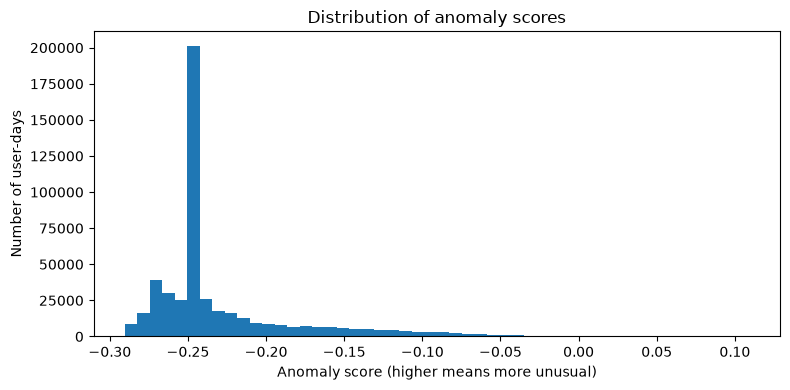

In [3]:
plt.figure(figsize=(8, 4))
plt.hist(results["anomaly_score"], bins=50)
plt.xlabel("Anomaly score (higher means more unusual)")
plt.ylabel("Number of user-days")
plt.title("Distribution of anomaly scores")
plt.tight_layout()
plt.show()

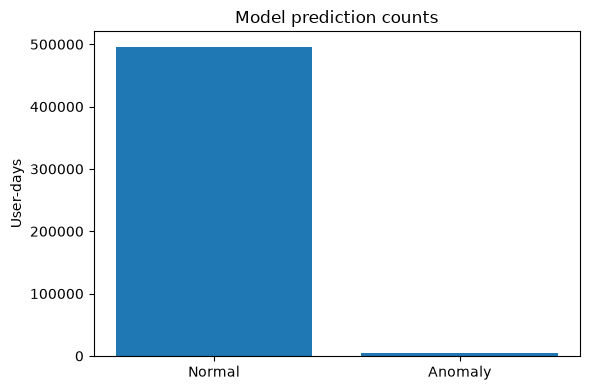

In [4]:
plt.figure(figsize=(6, 4))
plt.bar(["Normal", "Anomaly"], [(~results["is_anomaly"]).sum(), results["is_anomaly"].sum()])
plt.ylabel("User-days")
plt.title("Model prediction counts")
plt.tight_layout()
plt.show()